# Tech Challenge 9IADT - Fase 3
> Thiago de Melo Lima - RM370763 - Whatsapp: 11949389623

## 🧠 Dados e Modelos

#### O sistema ***dIAbetes*** será capaz de ajudar médicos(as) e equipes clínicas como um assistente médico especializado em diabetes.

## 📊 Dataset de perguntas sobre Diabetes:

Esta base de dados contém **138 registros** com perguntas sobre características e fatores que podem influenciar o diagnóstico de diabetes em um paciente.

> [clique aqui para mais informações sobre o dataset](https://github.com/abachaa/MedQuAD/tree/master/5_NIDDK_QA)
---



## 📁 Arquivos necessários

Na primeira execução do notebook no Google Colab, disponibilize os seguintes arquivos/diretórios no ambiente `/content/`:

### Dataset de fine-tuning

O diretório:

```text
/content/5_NIDDK_QA
```

contém os arquivos utilizados no processo de fine-tuning da LLM.

O notebook também realiza a sincronização desse diretório com o Google Drive para preservar o dataset entre diferentes sessões do Colab.

### Documento utilizado pelo RAG

O arquivo:

```text
/content/documento_diabetes.pdf
```

é o documento utilizado como fonte da base de conhecimento do RAG.

Durante a execução, o PDF é carregado, processado e transformado em chunks e registros estruturados, que posteriormente são utilizados para geração dos embeddings e construção da base vetorial.

> **Importante:** na primeira execução, os arquivos devem estar disponíveis no diretório `/content/` do Google Colab. Após a configuração do ambiente, o dataset `5_NIDDK_QA` é sincronizado com o Google Drive conforme o fluxo implementado no notebook.

Você pode encontrar e baixar o arquivo `documento_diabetes.pdf` e a pasta `5_NIDDK_QA`aqui: https://github.com/thiago-roock/dIAbetes-tech-challenge-fase3/tree/main/dataset/

In [1]:
PASTA_PROJETO = "/content/drive/MyDrive/Tech Challenge FIAP/Fase3"

PASTA_DATASET = f"{PASTA_PROJETO}/dataset"
PASTA_MODELOS = f"{PASTA_PROJETO}/modelos"
PASTA_RESULTADOS = f"{PASTA_PROJETO}/resultados"

In [2]:
import os

os.makedirs(PASTA_DATASET, exist_ok=True)
os.makedirs(PASTA_MODELOS, exist_ok=True)
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

In [3]:
from google.colab import drive
import shutil

# ===========================
# Montar Google Drive
# ===========================
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# ===========================
# Caminhos
# ===========================
origem_local = "/content/5_NIDDK_QA"
origem_drive = os.path.join(PASTA_DATASET, "5_NIDDK_QA")

print(origem_local)
print(origem_drive)
# ===========================
# Garantir estrutura
# ===========================
os.makedirs(PASTA_DATASET, exist_ok=True)

# ===========================
# Sincronização
# ===========================

# 1 - O dataset já existe no Drive (situação normal)
if os.path.exists(origem_drive):

    if not os.path.exists(origem_local):
        shutil.copytree(origem_drive, origem_local)
        print("✅ Dataset copiado do Google Drive para o Colab.")
    else:
        print("ℹ️ Dataset já disponível no Colab.")

# 2 - Primeira execução (só existe localmente)
elif os.path.exists(origem_local):

    shutil.copytree(origem_local, origem_drive)
    print("✅ Dataset salvo no Google Drive.")

# 3 - Não existe em lugar nenhum
else:
    raise FileNotFoundError(
        "Dataset não encontrado nem no Google Drive nem localmente."
    )

/content/5_NIDDK_QA
/content/drive/MyDrive/Tech Challenge FIAP/Fase3/dataset/5_NIDDK_QA
✅ Dataset copiado do Google Drive para o Colab.


# Importação das biblietecas e referências do projeto

In [4]:
# ==========================================================
# Instalação das bibliotecas
# ==========================================================

%%capture

import os
import re

if "COLAB_" not in "".join(os.environ.keys()):

    !pip install -q unsloth

else:

    import torch

    versao = re.match(
        r"[\d]+\.[\d]+",
        str(torch.__version__)
    ).group(0)

    xformers = (
        "xformers==" +
        {
            "2.10": "0.0.34",
            "2.9": "0.0.33.post1",
            "2.8": "0.0.32.post2",
        }.get(versao, "0.0.34")
    )

    # ======================================================
    # Dependências principais
    # ======================================================

    !pip install -q \
        sentencepiece \
        protobuf \
        datasets==4.3.0 \
        huggingface_hub>=0.34.0 \
        hf_transfer

    # ======================================================
    # Unsloth / Fine-tuning
    # ======================================================

    !pip install -q --no-deps \
        unsloth \
        unsloth_zoo \
        bitsandbytes \
        accelerate \
        {xformers} \
        peft \
        trl \
        triton

    !pip install -q --no-deps \
        torchao>=0.16.0

    # ======================================================
    # Transformers / TRL
    # ======================================================

    !pip install -q transformers==4.56.2

    !pip install -q --no-deps trl==0.22.2

    # ======================================================
    # RAG
    # ======================================================

    !pip install -q \
        pypdf \
        faiss-cpu \
        langchain-community \
        langchain-text-splitters \
        langchain-huggingface \
        sentence-transformers

    # ======================================================
    # LANGGRAPH
    # ======================================================
    !pip install grandalf -q


# Verificação do ambiente

In [5]:
# ==========================================================
# Verificação do ambiente
# ==========================================================

import torch
import transformers
import datasets
import unsloth
import os
from typing_extensions import TypedDict
from dotenv import load_dotenv
from langgraph.graph import StateGraph, END

try:
    from langchain.prompts import PromptTemplate
except Exception:
    PromptTemplate = None

print("=" * 80)
print("VERIFICAÇÃO DO AMBIENTE")
print("=" * 80)

# ==========================================================
# Fine-tuning
# ==========================================================

print("\n--- Fine-tuning ---")

print(f"PyTorch.......: {torch.__version__}")
print(f"Transformers..: {transformers.__version__}")
print(f"Datasets......: {datasets.__version__}")
print(f"Unsloth.......: {unsloth.__version__}")

# ==========================================================
# CUDA / GPU
# ==========================================================

print("\n--- CUDA / GPU ---")

cuda_disponivel = torch.cuda.is_available()

print(f"CUDA..........: {cuda_disponivel}")

if cuda_disponivel:
    print(f"GPU...........: {torch.cuda.get_device_name(0)}")
    print(f"CUDA versão...: {torch.version.cuda}")

# ==========================================================
# RAG
# ==========================================================

print("\n--- RAG ---")

try:
    import pypdf
    print(f"PyPDF.........: {pypdf.__version__}")
except Exception as erro:
    print(f"❌ PyPDF.......: {erro}")

try:
    import faiss
    print(f"FAISS.........: {faiss.__version__}")
except Exception as erro:
    print(f"❌ FAISS.......: {erro}")

try:
    import langchain
    print(f"LangChain.....: {langchain.__version__}")
except Exception as erro:
    print(f"❌ LangChain...: {erro}")

try:
    from langchain_community.document_loaders import PyPDFLoader
    print("PyPDFLoader...: OK")
except Exception as erro:
    print(f"❌ PyPDFLoader.: {erro}")

try:
    from langchain_text_splitters import RecursiveCharacterTextSplitter
    print("Text Splitter.: OK")
except Exception as erro:
    print(f"❌ TextSplitter: {erro}")

try:
    from langchain_community.vectorstores import FAISS
    print("LangChain FAISS: OK")
except Exception as erro:
    print(f"❌ LangChain FAISS: {erro}")

try:
    from langchain_huggingface import HuggingFaceEmbeddings
    print("HF Embeddings.: OK")
except Exception as erro:
    print(f"❌ HF Embeddings: {erro}")

try:
    import sentence_transformers
    print(
        f"Sentence Transformers: "
        f"{sentence_transformers.__version__}"
    )
except Exception as erro:
    print(f"❌ Sentence Transformers: {erro}")

print("\n" + "=" * 80)
print("VERIFICAÇÃO CONCLUÍDA")
print("=" * 80)

/usr/local/lib/python3.12/dist-packages/unsloth/__init__.py:1531: UserWarning: WARNING: Unsloth should be imported before [transformers] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
VERIFICAÇÃO DO AMBIENTE

--- Fine-tuning ---
PyTorch.......: 2.11.0+cu128
Transformers..: 4.56.2
Datasets......: 4.3.0
Unsloth.......: 2026.8.18

--- CUDA / GPU ---
CUDA..........: True
GPU...........: Tesla T4
CUDA versão...: 12.8

--- RAG ---
PyPDF.........: 6.16.1
FAISS.........: 1.15.0
LangChain.....: 1.3.13


/tmp/ipykernel_466/683800454.py:73: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


PyPDFLoader...: OK
Text Splitter.: OK
LangChain FAISS: OK
HF Embeddings.: OK
Sentence Transformers: 5.6.0

VERIFICAÇÃO CONCLUÍDA


# Carregamento do modelo

Nesta etapa, carregamos a LLM e o tokenizador utilizando o modelo previamente definido e as configurações de contexto e quantização.

In [6]:
from unsloth import FastLanguageModel

In [7]:
# Tamanho máximo do contexto
max_seq_length = 2048

# Utilizar 4 bits para economizar memória
load_in_4bit = True

# Tipo de dados
dtype = None

# Nome Modelo
nome_modelo = "unsloth/Llama-3.2-3B-Instruct-bnb-4bit"

In [8]:
modelo, tokenizador = FastLanguageModel.from_pretrained(
    model_name=nome_modelo,
    max_seq_length=max_seq_length,
    dtype=dtype,
    load_in_4bit=load_in_4bit,
)

==((====))==  Unsloth 2026.8.18: Fast Llama patching. Transformers: 4.56.2.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.34. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


In [9]:
FastLanguageModel.for_inference(modelo)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 3072, padding_idx=128004)
    (layers): ModuleList(
      (0-27): 28 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear4bit(in_features=3072, out_features=3072, bias=False)
          (k_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (v_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (o_proj): Linear4bit(in_features=3072, out_features=3072, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear4bit(in_features=3072, out_features=8192, bias=False)
          (up_proj): Linear4bit(in_features=3072, out_features=8192, bias=False)
          (down_proj): Linear4bit(in_features=8192, out_features=3072, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm

### Breve teste do modelo

In [10]:
mensagens = [
    {
        "role": "user",
        "content": "O que é diabetes tipo 2?"
    }
]

entrada = tokenizador.apply_chat_template(
    mensagens,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
).to("cuda")

saida = modelo.generate(
    input_ids=entrada,
    max_new_tokens=256,
    temperature=0.2,
)

print(tokenizador.decode(saida[0], skip_special_tokens=True))

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


system

Cutting Knowledge Date: December 2023
Today Date: 17 Aug 2026

user

O que é diabetes tipo 2?assistant

Olá! Vou explicar o que é diabetes tipo 2 de forma clara e concisa.

**O que é diabetes tipo 2?**

A diabetes tipo 2 é uma doença crônica que afeta a forma como o corpo regula o açúcar no sangue. Ela ocorre quando o corpo não consegue usar a insulina, um hormônio produzido pelas glândulas endócrinas que regula a quantidade de açúcar no sangue.

**Causas da diabetes tipo 2**

A diabetes tipo 2 é causada por uma combinação de fatores, incluindo:

*   Genética: A predisposição genética pode aumentar o risco de desenvolver diabetes tipo 2.
*   Obesidade: A obesidade é um dos principais fatores de risco para diabetes tipo 2.
*   Inatividade física: A falta de atividade física pode aumentar o risco de desenvolver diabetes tipo 2.
*   Alimentação: Uma dieta rica em açúcar e gordura pode contribuir para o desenvolvimento da diabetes tipo 2.
*   Fatores ambientais


# Processamento e tratamento dos arquivos que vamos utilizar no fine tuning

In [11]:
caminho = origem_drive
arquivos = sorted(
    [
        arquivo
        for arquivo in os.listdir(caminho)
        if arquivo.endswith(".xml")
    ]
)

print(f"Quantidade de XMLs: {len(arquivos)}")
print("\nPrimeiros arquivos:")
print(arquivos[:10])

Quantidade de XMLs: 157

Primeiros arquivos:
['0000001.xml', '0000002.xml', '0000003.xml', '0000004.xml', '0000005.xml', '0000007.xml', '0000008.xml', '0000009.xml', '0000010.xml', '0000011.xml']


In [12]:
import xml.etree.ElementTree as ET

def explorar_xml(elemento, nivel=0):
    """
    Exibe recursivamente toda a estrutura de um XML.
    """

    indentacao = "    " * nivel

    print(f"{indentacao}{'=' * 80}")
    print(f"{indentacao}Tag: {elemento.tag}")

    if elemento.attrib:
        print(f"{indentacao}Atributos:")
        for chave, valor in elemento.attrib.items():
            print(f"{indentacao}  {chave}: {valor}")

    texto = (elemento.text or "").strip()

    if texto:
        texto = texto.replace("\n", " ")

        if len(texto) > 300:
            texto = texto[:300] + "..."

        print(f"{indentacao}Conteúdo:")
        print(f"{indentacao}{texto}")

    for filho in elemento:
        explorar_xml(filho, nivel + 1)

In [13]:
arquivo = os.path.join(caminho, arquivos[0])

arvore = ET.parse(arquivo)
raiz = arvore.getroot()

explorar_xml(raiz)

Tag: Document
Atributos:
  id: 0000001
  source: NIDDK
  url: http://www.niddk.nih.gov/health-information/health-topics/endocrine/acromegaly/Pages/fact-sheet.aspx
    Tag: Focus
    Conteúdo:
    Acromegaly
    Tag: FocusAnnotations
        Tag: UMLS
            Tag: CUIs
                Tag: CUI
                Conteúdo:
                C0001206
            Tag: SemanticTypes
                Tag: SemanticType
                Conteúdo:
                T047
            Tag: SemanticGroup
            Conteúdo:
            Disorders
    Tag: QAPairs
        Tag: QAPair
        Atributos:
          pid: 1
            Tag: Question
            Atributos:
              qid: 0000001-1
              qtype: information
            Conteúdo:
            What is (are) Acromegaly ?
            Tag: Answer
            Conteúdo:
            Acromegaly is a hormonal disorder that results from too much growth hormone (GH) in the body. The pituitary, a small gland in the brain, makes GH. In acromegaly,

In [14]:
import os
import xml.etree.ElementTree as ET
import pandas as pd

def carregar_medquad(caminho):
    """
    Lê todos os arquivos XML do MedQuAD e retorna um DataFrame.
    """

    registros = []

    arquivos = sorted(
        arquivo
        for arquivo in os.listdir(caminho)
        if arquivo.endswith(".xml")
    )

    for arquivo in arquivos:

        caminho_arquivo = os.path.join(caminho, arquivo)

        try:
            arvore = ET.parse(caminho_arquivo)
            raiz = arvore.getroot()

            foco = raiz.findtext("Focus", default="").strip()

            pares = raiz.find("QAPairs")

            if pares is None:
                continue

            for par in pares:

                pergunta = par.find("Question")
                resposta = par.find("Answer")

                registros.append({
                    "arquivo": arquivo,
                    "foco": foco,
                    "tipo_pergunta": pergunta.get("qtype", ""),
                    "id_pergunta": pergunta.get("qid", ""),
                    "pergunta": (pergunta.text or "").strip(),
                    "resposta": (resposta.text or "").strip()
                })

        except Exception as erro:
            print(f"Erro ao processar {arquivo}: {erro}")

    return pd.DataFrame(registros)

In [15]:
df = carregar_medquad(caminho)

In [16]:
# Apenas registros relacionados à diabetes

palavras_chave = [
    "diabetes",
    "diabetic",
    "hypoglycemia",
    "hyperglycemia",
    "insulin",
    "prediabetes"
]

df = df[
    df["foco"].str.lower().apply(
        lambda foco: any(palavra in foco for palavra in palavras_chave)
    )
].reset_index(drop=True)

In [17]:
df = (
    df
    .drop_duplicates(subset=["pergunta", "resposta"])
    .reset_index(drop=True)
)

In [18]:
print(f"Quantidade de registros: {len(df)}")
print()

print(df["foco"].value_counts())

Quantidade de registros: 135

foco
Diabetic Neuropathies: The Nerve Damage of Diabetes                                                 12
Diabetes, Heart Disease, and Stroke                                                                 11
Diabetic Kidney Disease                                                                             10
What I need to know about Gestational Diabetes                                                      10
Insulin Resistance and Prediabetes                                                                   9
Am I at Risk for Type 2 Diabetes? Taking Steps to Lower Your Risk of Getting Diabetes                8
Financial Help for Diabetes Care                                                                     8
Hypoglycemia                                                                                         7
Diagnosis of Diabetes and Prediabetes                                                                7
Causes of Diabetes                    

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   arquivo        135 non-null    object
 1   foco           135 non-null    object
 2   tipo_pergunta  135 non-null    object
 3   id_pergunta    135 non-null    object
 4   pergunta       135 non-null    object
 5   resposta       135 non-null    object
dtypes: object(6)
memory usage: 6.5+ KB


In [20]:
df.sample(10)

,arquivo,foco,tipo_pergunta,id_pergunta,pergunta,resposta
133,0000153.xml,Kidney Disease of Diabetes,prevention,0000153-9,How to prevent Kidney Disease of Diabetes ?,Blood Pressure Medicines\n \nSc...
92,0000054.xml,Prevent diabetes problems: Keep your diabetes ...,exams and tests,0000054-14,How to diagnose Prevent diabetes problems: Kee...,"This chart lists important tests, exams, and v..."
38,0000034.xml,Diabetic Neuropathies: The Nerve Damage of Dia...,symptoms,0000034-3,What are the symptoms of Diabetic Neuropathies...,Symptoms depend on the type of neuropathy and ...
72,0000043.xml,I Can Lower My Risk for Type 2 Diabetes: A Gui...,susceptibility,0000043-4,Who is at risk for I Can Lower My Risk for Typ...,- My mother had diabetes when I was born. - ...
134,0000153.xml,Kidney Disease of Diabetes,considerations,0000153-15,What to do for Kidney Disease of Diabetes ?,- Diabetes is the leading cause of chronic kid...
5,0000022.xml,Am I at Risk for Type 2 Diabetes? Taking Steps...,susceptibility,0000022-7,Who is at risk for Am I at Risk for Type 2 Dia...,"To find out your risk for type 2 diabetes, che..."
91,0000054.xml,Prevent diabetes problems: Keep your diabetes ...,prevention,0000054-12,How to prevent Prevent diabetes problems: Keep...,You can take steps each day to prevent diabete...
27,0000033.xml,Diabetic Kidney Disease,information,0000033-2,What is (are) Diabetic Kidney Disease ?,"The kidneys are two bean-shaped organs, each a..."
102,0000058.xml,Prevent diabetes problems: Keep your kidneys h...,information,0000058-3,What is (are) Prevent diabetes problems: Keep ...,Blood pressure is the force of blood flow insi...
125,0000079.xml,What I need to know about Physical Activity an...,considerations,0000079-6,What to do for What I need to know about Physi...,- Starting a physical activity program can hel...


In [21]:
dataset = []

for _, linha in df.iterrows():

    dataset.append({
        "messages": [
            {
                "role": "user",
                "content": linha["pergunta"]
            },
            {
                "role": "assistant",
                "content": linha["resposta"]
            }
        ]
    })

print(f"Total de exemplos: {len(dataset)}")
print(dataset[0])

Total de exemplos: 135
{'messages': [{'role': 'user', 'content': 'What is (are) 4 Steps to Manage Your Diabetes for Life ?'}, {'role': 'assistant', 'content': 'What is diabetes?\n                \nThere are three main types of diabetes:\n                \n- Type 1 diabetes  Your body does not make insulin. This is a problem because you need insulin to take the sugar (glucose) from the foods you eat and turn it into energy for your body. You need to take insulin every day to live.   - Type 2 diabetes  Your body does not make or use insulin well. You may need to take pills or insulin to help control your diabetes. Type 2 is the most common type of diabetes.   - Gestational (jest-TAY-shun-al) diabetes  Some women get this kind of diabetes when they are pregnant. Most of the time, it goes away after the baby is born. But even if it goes away, these women and their children have a greater chance of getting diabetes later in life.\n                \nYou are the most important member of your 

In [22]:
import json

# Caminho onde o dataset será salvo
caminho_dataset = os.path.join(
    PASTA_DATASET,
    "dataset_ajuste_fino.jsonl"
)

with open(caminho_dataset, "w", encoding="utf-8") as arquivo:
    for exemplo in dataset:
        arquivo.write(
            json.dumps(exemplo, ensure_ascii=False) + "\n"
        )

print(f"✅ Dataset salvo em:\n{caminho_dataset}")

✅ Dataset salvo em:
/content/drive/MyDrive/Tech Challenge FIAP/Fase3/dataset/dataset_ajuste_fino.jsonl


In [23]:
caminho_csv = os.path.join(
    PASTA_DATASET,
    "dataset_ajuste_fino.csv"
)

df.to_csv(
    caminho_csv,
    index=False,
    encoding="utf-8-sig"
)

print(f"✅ CSV salvo em:\n{caminho_csv}")

✅ CSV salvo em:
/content/drive/MyDrive/Tech Challenge FIAP/Fase3/dataset/dataset_ajuste_fino.csv


In [24]:
print(f"Total de exemplos: {len(dataset)}")
print()

print("Primeiro exemplo:")
print(json.dumps(dataset[0], indent=2, ensure_ascii=False))

Total de exemplos: 135

Primeiro exemplo:
{
  "messages": [
    {
      "role": "user",
      "content": "What is (are) 4 Steps to Manage Your Diabetes for Life ?"
    },
    {
      "role": "assistant",
      "content": "What is diabetes?\n                \nThere are three main types of diabetes:\n                \n- Type 1 diabetes  Your body does not make insulin. This is a problem because you need insulin to take the sugar (glucose) from the foods you eat and turn it into energy for your body. You need to take insulin every day to live.   - Type 2 diabetes  Your body does not make or use insulin well. You may need to take pills or insulin to help control your diabetes. Type 2 is the most common type of diabetes.   - Gestational (jest-TAY-shun-al) diabetes  Some women get this kind of diabetes when they are pregnant. Most of the time, it goes away after the baby is born. But even if it goes away, these women and their children have a greater chance of getting diabetes later in life.

In [25]:
mensagem_sistema = (
    "Você é um assistente especializado em diabetes. "
    "Responda utilizando linguagem clara, objetiva e baseada em evidências científicas. "
    "Suas respostas possuem caráter exclusivamente informativo e não substituem a avaliação "
    "de um médico ou outro profissional de saúde."
)

In [26]:
from datasets import load_dataset

dataset = load_dataset(
    "json",
    data_files=caminho_dataset,
    split="train"
)

print(dataset)
print(dataset[0])

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['messages'],
    num_rows: 135
})
{'messages': [{'role': 'user', 'content': 'What is (are) 4 Steps to Manage Your Diabetes for Life ?'}, {'role': 'assistant', 'content': 'What is diabetes?\n                \nThere are three main types of diabetes:\n                \n- Type 1 diabetes  Your body does not make insulin. This is a problem because you need insulin to take the sugar (glucose) from the foods you eat and turn it into energy for your body. You need to take insulin every day to live.   - Type 2 diabetes  Your body does not make or use insulin well. You may need to take pills or insulin to help control your diabetes. Type 2 is the most common type of diabetes.   - Gestational (jest-TAY-shun-al) diabetes  Some women get this kind of diabetes when they are pregnant. Most of the time, it goes away after the baby is born. But even if it goes away, these women and their children have a greater chance of getting diabetes later in life.\n                \nYou ar

In [27]:
from unsloth.chat_templates import get_chat_template

tokenizador = get_chat_template(
    tokenizador,
    chat_template="llama-3.1",
)

In [28]:
def aplicar_template(exemplo):

    return {
        "text": tokenizador.apply_chat_template(
            exemplo["messages"],
            tokenize=False,
            add_generation_prompt=False,
        )
    }

In [29]:
dataset = dataset.map(aplicar_template)

Map:   0%|          | 0/135 [00:00<?, ? examples/s]

In [30]:
print(dataset.column_names)
print(dataset[0])

['messages', 'text']
{'messages': [{'role': 'user', 'content': 'What is (are) 4 Steps to Manage Your Diabetes for Life ?'}, {'role': 'assistant', 'content': 'What is diabetes?\n                \nThere are three main types of diabetes:\n                \n- Type 1 diabetes  Your body does not make insulin. This is a problem because you need insulin to take the sugar (glucose) from the foods you eat and turn it into energy for your body. You need to take insulin every day to live.   - Type 2 diabetes  Your body does not make or use insulin well. You may need to take pills or insulin to help control your diabetes. Type 2 is the most common type of diabetes.   - Gestational (jest-TAY-shun-al) diabetes  Some women get this kind of diabetes when they are pregnant. Most of the time, it goes away after the baby is born. But even if it goes away, these women and their children have a greater chance of getting diabetes later in life.\n                \nYou are the most important member of your he

In [31]:
print(dataset[0]["text"])

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

<|eot_id|><|start_header_id|>user<|end_header_id|>

What is (are) 4 Steps to Manage Your Diabetes for Life ?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

What is diabetes?
                
There are three main types of diabetes:
                
- Type 1 diabetes  Your body does not make insulin. This is a problem because you need insulin to take the sugar (glucose) from the foods you eat and turn it into energy for your body. You need to take insulin every day to live.   - Type 2 diabetes  Your body does not make or use insulin well. You may need to take pills or insulin to help control your diabetes. Type 2 is the most common type of diabetes.   - Gestational (jest-TAY-shun-al) diabetes  Some women get this kind of diabetes when they are pregnant. Most of the time, it goes away after the baby is born. But even if it goes away, these women and their c

# Fining-tuning

In [32]:
modelo = FastLanguageModel.get_peft_model(
    modelo,

    r=16,

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],

    lora_alpha=16,
    lora_dropout=0,
    bias="none",

    use_gradient_checkpointing="unsloth",

    random_state=7,

    use_rslora=False,
)

Unsloth 2026.8.18 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


In [33]:
from trl import SFTTrainer
from transformers import TrainingArguments

In [34]:
from trl import SFTTrainer, SFTConfig
from transformers import DataCollatorForSeq2Seq

trainer = SFTTrainer(
    model=modelo,
    processing_class=tokenizador,

    train_dataset=dataset,

    dataset_text_field="text",
    max_seq_length=2048,

    data_collator=DataCollatorForSeq2Seq(
        tokenizer=tokenizador
    ),

    packing=False,

    args=SFTConfig(

        # ==========================================
        # Diretório de saída
        # ==========================================
        output_dir=PASTA_RESULTADOS,
        overwrite_output_dir=False,

        # ==========================================
        # Treinamento
        # ==========================================
        num_train_epochs=3,

        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,

        learning_rate=2e-4,
        warmup_steps=5,

        optim="adamw_8bit",
        weight_decay=0.001,
        lr_scheduler_type="linear",

        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),

        # ==========================================
        # Logs
        # ==========================================
        logging_strategy="steps",
        logging_steps=1,

        # ==========================================
        # Checkpoints
        # ==========================================
        save_strategy="steps",
        save_steps=10,
        save_total_limit=3,
        save_safetensors=True,

        # ==========================================
        # Não teremos validação
        # ==========================================
        eval_strategy="no",

        # ==========================================
        # Reprodutibilidade
        # ==========================================
        seed=7,

        # ==========================================
        # Relatórios
        # ==========================================
        report_to="none",
    ),
)

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/135 [00:00<?, ? examples/s]

In [35]:
import glob
import os

checkpoints = sorted(
    glob.glob(
        os.path.join(PASTA_RESULTADOS, "checkpoint-*")
    )
)

if checkpoints:

    ultimo_checkpoint = checkpoints[-1]

    print("=" * 70)
    print("Checkpoint encontrado")
    print(ultimo_checkpoint)
    print("=" * 70)

    resultado = trainer.train(
        resume_from_checkpoint=ultimo_checkpoint
    )

else:

    print("=" * 70)
    print("Nenhum checkpoint encontrado.")
    print("Iniciando treinamento do zero.")
    print("=" * 70)

    resultado = trainer.train()

Checkpoint encontrado
/content/drive/MyDrive/Tech Challenge FIAP/Fase3/resultados/checkpoint-51


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 135 | Num Epochs = 3 | Total steps = 51
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 24,313,856 of 3,237,063,680 (0.75% trained)


Step,Training Loss


In [36]:
print("=" * 70)
print("Resumo do treinamento")
print("=" * 70)

print(f"Modelo base...............: {nome_modelo}")
print(f"Quantidade de exemplos....: {len(dataset)}")

print(f"Número de épocas..........: {trainer.args.num_train_epochs}")
print(f"Total de passos...........: {trainer.state.max_steps}")

print(f"Batch Size................: {trainer.args.per_device_train_batch_size}")
print(f"Acúmulo de gradientes.....: {trainer.args.gradient_accumulation_steps}")
print(
    f"Batch efetivo.............: "
    f"{trainer.args.per_device_train_batch_size * trainer.args.gradient_accumulation_steps}"
)

print(f"Taxa de aprendizado.......: {trainer.args.learning_rate}")
print(f"Otimizador.................: {trainer.args.optim}")
print(f"Scheduler.................: {trainer.args.lr_scheduler_type}")
print(f"Weight Decay..............: {trainer.args.weight_decay}")

print(f"Checkpoints...............: a cada {trainer.args.save_steps} passos")
print(f"Diretório de saída........: {trainer.args.output_dir}")

print("=" * 70)

Resumo do treinamento
Modelo base...............: unsloth/Llama-3.2-3B-Instruct-bnb-4bit
Quantidade de exemplos....: 135
Número de épocas..........: 3
Total de passos...........: 51
Batch Size................: 2
Acúmulo de gradientes.....: 4
Batch efetivo.............: 8
Taxa de aprendizado.......: 0.0002
Otimizador.................: OptimizerNames.ADAMW_8BIT
Scheduler.................: SchedulerType.LINEAR
Weight Decay..............: 0.001
Checkpoints...............: a cada 10 passos
Diretório de saída........: /content/drive/MyDrive/Tech Challenge FIAP/Fase3/resultados


In [37]:
import json
import os

config_treinamento = {
    "modelo_base": nome_modelo,
    "dataset": len(dataset),
    "epocas": trainer.args.num_train_epochs,
    "batch_size": trainer.args.per_device_train_batch_size,
    "gradient_accumulation": trainer.args.gradient_accumulation_steps,
    "learning_rate": trainer.args.learning_rate,
    "optimizer": str(trainer.args.optim),
    "scheduler": str(trainer.args.lr_scheduler_type),
    "weight_decay": trainer.args.weight_decay,
    "total_steps": trainer.state.max_steps,
}

with open(
    os.path.join(PASTA_MODELOS, "config_treinamento.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config_treinamento, f, indent=4, ensure_ascii=False)

print("✅ Configuração do treinamento salva.")

✅ Configuração do treinamento salva.


In [38]:
CAMINHO_MODELO = os.path.join(
    PASTA_MODELOS,
    "llama32_diabetes_lora"
)

modelo.save_pretrained(CAMINHO_MODELO)
tokenizador.save_pretrained(CAMINHO_MODELO)

print("✅ Modelo salvo com sucesso!")

✅ Modelo salvo com sucesso!


In [39]:
from unsloth import FastLanguageModel

FastLanguageModel.for_inference(modelo)

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): LlamaForCausalLM(
      (model): LlamaModel(
        (embed_tokens): Embedding(128256, 3072, padding_idx=128004)
        (layers): ModuleList(
          (0-27): 28 x LlamaDecoderLayer(
            (self_attn): LlamaAttention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=3072, out_features=3072, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Identity()
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=3072, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=3072, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lor

In [40]:
modelo.print_trainable_parameters()

trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511


In [41]:
import torch

def perguntar(pergunta):

    mensagens = [
        {
            "role": "system",
            "content": (
                "You are a medical assistant specialized in diabetes. "
                "Answer clearly, objectively and using evidence-based medical information. "
                "Avoid repeating information or generating redundant text. "
                "Provide concise but complete answers. "
                "Stop generating once the answer is complete."
            )
        },
        {
            "role": "user",
            "content": pergunta
        }
    ]

    entrada = tokenizador.apply_chat_template(
        mensagens,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    ).to("cuda")

    with torch.no_grad():

        saida = modelo.generate(
            input_ids=entrada,

            max_new_tokens=256,

            do_sample=False,

            repetition_penalty=1.20,

            no_repeat_ngram_size=3,

            use_cache=True,

            eos_token_id=tokenizador.eos_token_id,
            pad_token_id=tokenizador.eos_token_id,
        )

    resposta = tokenizador.decode(
        saida[0][entrada.shape[-1]:],
        skip_special_tokens=True,
    )

    return resposta.strip()

In [42]:
def testar(pergunta):

    print("=" * 100)
    print("QUESTION")
    print("-" * 100)
    print(pergunta)

    print("\nANSWER")
    print("-" * 100)
    print(perguntar(pergunta))

    print("=" * 100)

In [43]:
testar("What is Type 2 diabetes?")
testar("What is hypoglycemia?")
testar("What is diabetic neuropathy?")
testar("How can diabetes be prevented?")

QUESTION
----------------------------------------------------------------------------------------------------
What is Type 2 diabetes?

ANSWER
----------------------------------------------------------------------------------------------------
Type 2 Diabetes is a condition that occurs when your body does not make enough insulin to keep you healthy. Insulin helps move glucose from food into cells throughout your body. When you eat, especially foods high in carbohydrates, your digestive system breaks down those carbs into glucose. Your pancreas then releases insulin into your bloodstream. The insulin carries glucose to all of your cells where it can be used for energy.
                
Insulin also stores excess glucose as glycogen in liver and muscle cells. If there is too much glucose in your blood, your kidneys remove some of it through urine. Excess glucose in the urine causes your blood glucose level to rise above normal levels. High blood glucose over time damages nerves, eyes, he

FIM DO FINE TUNING

INICIO DA PARTE 2 - Criação de assistente médico com LangChain

## prontuários de pacientes simulados

In [157]:
pacientes = [
  {
    "id": 1,
    "cpf": "123.456.789-01",
    "nome": "Maria Silva",
    "sexo": "Feminino",
    "idade": 58,
    "data_nascimento": "1968-03-12",
    "diagnostico": {
      "principal": "Diabetes Tipo 2",
      "tempo_diagnostico_anos": 12,
      "comorbidades": [
        "Hipertensão Arterial",
        "Obesidade Grau I"
      ]
    },
    "dados_antropometricos": {
      "altura_m": 1.62,
      "peso_kg": 81,
      "imc": 30.9
    },
    "sinais_vitais": {
      "pressao_arterial": "145/90",
      "frequencia_cardiaca": 82
    },
    "exames": {
      "hba1c": { "valor": 8.4, "data": "2026-07-10" },
      "glicemia_jejum": { "valor": 176, "data": "2026-07-10" },
      "creatinina": 1.1,
      "tfg": 71,
      "ldl": 118,
      "hdl": 43,
      "triglicerideos": 198
    },
    "medicamentos": [
      { "nome": "Metformina", "dose": "850 mg", "frequencia": "2x ao dia" },
      { "nome": "Empagliflozina", "dose": "25 mg", "frequencia": "1x ao dia" },
      { "nome": "Losartana", "dose": "50 mg", "frequencia": "1x ao dia" }
    ],
    "alergias": ["Penicilina"],
    "complicacoes": ["Hipertensão"],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Social",
      "atividade_fisica": "2x por semana",
      "alimentacao": "Necessita melhorar"
    },
    "historico_consultas": [
      {
        "data": "2026-05-12",
        "observacao": "Controle glicêmico inadequado."
      },
      {
        "data": "2026-07-10",
        "observacao": "Reforçadas orientações nutricionais."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza", "COVID-19", "Hepatite B"]
  },
  {
    "id": 2,
    "cpf": "234.567.890-12",
    "nome": "João Pereira",
    "sexo": "Masculino",
    "idade": 29,
    "data_nascimento": "1997-02-18",
    "diagnostico": {
      "principal": "Diabetes Tipo 1",
      "tempo_diagnostico_anos": 15,
      "comorbidades": []
    },
    "dados_antropometricos": {
      "altura_m": 1.78,
      "peso_kg": 73,
      "imc": 23.0
    },
    "sinais_vitais": {
      "pressao_arterial": "118/74",
      "frequencia_cardiaca": 70
    },
    "exames": {
      "hba1c": { "valor": 7.1, "data": "2026-07-05" },
      "glicemia_jejum": { "valor": 121, "data": "2026-07-05" },
      "creatinina": 0.9,
      "tfg": 105,
      "ldl": 82,
      "hdl": 55,
      "triglicerideos": 96
    },
    "medicamentos": [
      { "nome": "Insulina Glargina", "dose": "24 UI", "frequencia": "1x ao dia" },
      { "nome": "Insulina Aspart", "dose": "Conforme refeição", "frequencia": "3x ao dia" }
    ],
    "alergias": [],
    "complicacoes": [],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "5x por semana",
      "alimentacao": "Boa"
    },
    "historico_consultas": [
      {
        "data": "2026-07-05",
        "observacao": "Excelente adesão ao tratamento."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza", "COVID-19"]
  },
  {
    "id": 3,
    "cpf": "345.678.901-23",
    "nome": "Ana Costa",
    "sexo": "Feminino",
    "idade": 34,
    "data_nascimento": "1992-11-01",
    "diagnostico": {
      "principal": "Diabetes Gestacional",
      "tempo_diagnostico_anos": 0,
      "comorbidades": []
    },
    "dados_antropometricos": {
      "altura_m": 1.66,
      "peso_kg": 74,
      "imc": 26.9
    },
    "sinais_vitais": {
      "pressao_arterial": "118/78",
      "frequencia_cardiaca": 84
    },
    "exames": {
      "hba1c": { "valor": 5.9, "data": "2026-07-18" },
      "glicemia_jejum": { "valor": 97, "data": "2026-07-18" },
      "creatinina": 0.7,
      "tfg": 120,
      "ldl": 91,
      "hdl": 58,
      "triglicerideos": 124
    },
    "medicamentos": [],
    "alergias": [],
    "complicacoes": [],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "Caminhada leve",
      "alimentacao": "Controlada"
    },
    "historico_consultas": [
      {
        "data": "2026-07-18",
        "observacao": "Gestação de 28 semanas. Controle satisfatório."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza", "dTpa"]
  },
  {
    "id": 4,
    "cpf": "456.789.012-34",
    "nome": "Carlos Mendes",
    "sexo": "Masculino",
    "idade": 67,
    "data_nascimento": "1959-01-09",
    "diagnostico": {
      "principal": "Diabetes Tipo 2",
      "tempo_diagnostico_anos": 20,
      "comorbidades": [
        "Hipertensão"
      ]
    },
    "dados_antropometricos": {
      "altura_m": 1.70,
      "peso_kg": 92,
      "imc": 31.8
    },
    "sinais_vitais": {
      "pressao_arterial": "160/98",
      "frequencia_cardiaca": 88
    },
    "exames": {
      "hba1c": { "valor": 10.2, "data": "2026-07-02" },
      "glicemia_jejum": { "valor": 248, "data": "2026-07-02" },
      "creatinina": 1.3,
      "tfg": 58,
      "ldl": 142,
      "hdl": 38,
      "triglicerideos": 236
    },
    "medicamentos": [
      { "nome": "Metformina", "dose": "850 mg", "frequencia": "2x ao dia" },
      { "nome": "Insulina NPH", "dose": "30 UI", "frequencia": "2x ao dia" }
    ],
    "alergias": [],
    "complicacoes": [
      "Neuropatia diabética"
    ],
    "habitos": {
      "tabagismo": 1,
      "alcool": "Social",
      "atividade_fisica": "Sedentário",
      "alimentacao": "Rica em carboidratos"
    },
    "historico_consultas": [
      {
        "data": "2026-07-02",
        "observacao": "Necessita intensificar tratamento."
      }
    ],
    "internacoes": [
      {
        "data": "2025-11-12",
        "motivo": "Hiperglicemia"
      }
    ],
    "vacinas": ["Influenza"]
  },
  {
    "id": 5,
    "cpf": "567.890.123-45",
    "nome": "Fernanda Rocha",
    "sexo": "Feminino",
    "idade": 45,
    "data_nascimento": "1981-06-22",
    "diagnostico": {
      "principal": "Pré-diabetes",
      "tempo_diagnostico_anos": 1,
      "comorbidades": []
    },
    "dados_antropometricos": {
      "altura_m": 1.60,
      "peso_kg": 77,
      "imc": 30.1
    },
    "sinais_vitais": {
      "pressao_arterial": "130/82",
      "frequencia_cardiaca": 76
    },
    "exames": {
      "hba1c": { "valor": 6.1, "data": "2026-07-14" },
      "glicemia_jejum": { "valor": 109, "data": "2026-07-14" },
      "creatinina": 0.8,
      "tfg": 102,
      "ldl": 104,
      "hdl": 48,
      "triglicerideos": 161
    },
    "medicamentos": [],
    "alergias": [],
    "complicacoes": [],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Raramente",
      "atividade_fisica": "1x por semana",
      "alimentacao": "Necessita reduzir açúcar"
    },
    "historico_consultas": [
      {
        "data": "2026-07-14",
        "observacao": "Orientada sobre mudança de estilo de vida."
      }
    ],
    "internacoes": [],
    "vacinas": ["COVID-19", "Influenza"]
  },
  {
    "id": 6,
    "cpf": "678.901.234-56",
    "nome": "Ricardo Alves",
    "sexo": "Masculino",
    "idade": 52,
    "data_nascimento": "1974-08-15",
    "diagnostico": {
      "principal": "Diabetes Tipo 2",
      "tempo_diagnostico_anos": 8,
      "comorbidades": []
    },
    "dados_antropometricos": {
      "altura_m": 1.75,
      "peso_kg": 88,
      "imc": 28.7
    },
    "sinais_vitais": {
      "pressao_arterial": "124/78",
      "frequencia_cardiaca": 71
    },
    "exames": {
      "hba1c": { "valor": 6.8, "data": "2026-07-08" },
      "glicemia_jejum": { "valor": 115, "data": "2026-07-08" },
      "creatinina": 0.9,
      "tfg": 96,
      "ldl": 89,
      "hdl": 54,
      "triglicerideos": 119
    },
    "medicamentos": [
      { "nome": "Metformina", "dose": "850 mg", "frequencia": "2x ao dia" }
    ],
    "alergias": ["Dipirona"],
    "complicacoes": [],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "4x por semana",
      "alimentacao": "Balanceada"
    },
    "historico_consultas": [
      {
        "data": "2026-07-08",
        "observacao": "Controle glicêmico adequado."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza", "COVID-19"]
  },
  {
    "id": 7,
    "cpf": "789.012.345-67",
    "nome": "Luciana Gomes",
    "sexo": "Feminino",
    "idade": 39,
    "data_nascimento": "1987-09-05",
    "diagnostico": {
      "principal": "Diabetes Tipo 1",
      "tempo_diagnostico_anos": 18,
      "comorbidades": []
    },
    "dados_antropometricos": {
      "altura_m": 1.68,
      "peso_kg": 65,
      "imc": 23.0
    },
    "sinais_vitais": {
      "pressao_arterial": "120/76",
      "frequencia_cardiaca": 74
    },
    "exames": {
      "hba1c": { "valor": 7.8, "data": "2026-07-09" },
      "glicemia_jejum": { "valor": 142, "data": "2026-07-09" },
      "creatinina": 0.8,
      "tfg": 99,
      "ldl": 92,
      "hdl": 56,
      "triglicerideos": 104
    },
    "medicamentos": [
      { "nome": "Insulina Degludeca", "dose": "22 UI", "frequencia": "1x ao dia" },
      { "nome": "Insulina Lispro", "dose": "Conforme refeição", "frequencia": "3x ao dia" }
    ],
    "alergias": [],
    "complicacoes": [
      "Hipoglicemias recorrentes"
    ],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "3x por semana",
      "alimentacao": "Boa"
    },
    "historico_consultas": [
      {
        "data": "2026-07-09",
        "observacao": "Ajustada dose da insulina basal."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza"]
  },
  {
    "id": 8,
    "cpf": "890.123.456-78",
    "nome": "Pedro Lima",
    "sexo": "Masculino",
    "idade": 61,
    "data_nascimento": "1965-12-19",
    "diagnostico": {
      "principal": "Diabetes Tipo 2",
      "tempo_diagnostico_anos": 16,
      "comorbidades": [
        "Doença Renal Crônica"
      ]
    },
    "dados_antropometricos": {
      "altura_m": 1.72,
      "peso_kg": 84,
      "imc": 28.4
    },
    "sinais_vitais": {
      "pressao_arterial": "148/92",
      "frequencia_cardiaca": 80
    },
    "exames": {
      "hba1c": { "valor": 9.3, "data": "2026-07-03" },
      "glicemia_jejum": { "valor": 214, "data": "2026-07-03" },
      "creatinina": 2.0,
      "tfg": 39,
      "ldl": 116,
      "hdl": 39,
      "triglicerideos": 208
    },
    "medicamentos": [
      { "nome": "Metformina", "dose": "500 mg", "frequencia": "2x ao dia" },
      { "nome": "Gliclazida", "dose": "60 mg", "frequencia": "1x ao dia" }
    ],
    "alergias": [],
    "complicacoes": [
      "Doença renal diabética"
    ],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "Sedentário",
      "alimentacao": "Irregular"
    },
    "historico_consultas": [
      {
        "data": "2026-07-03",
        "observacao": "Encaminhado para nefrologista."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza"]
  },
  {
    "id": 9,
    "cpf": "901.234.567-89",
    "nome": "Juliana Martins",
    "sexo": "Feminino",
    "idade": 26,
    "data_nascimento": "2000-04-28",
    "diagnostico": {
      "principal": "Diabetes Tipo 1",
      "tempo_diagnostico_anos": 3,
      "comorbidades": []
    },
    "dados_antropometricos": {
      "altura_m": 1.63,
      "peso_kg": 59,
      "imc": 22.2
    },
    "sinais_vitais": {
      "pressao_arterial": "112/70",
      "frequencia_cardiaca": 68
    },
    "exames": {
      "hba1c": { "valor": 6.5, "data": "2026-07-21" },
      "glicemia_jejum": { "valor": 108, "data": "2026-07-21" },
      "creatinina": 0.8,
      "tfg": 112,
      "ldl": 84,
      "hdl": 60,
      "triglicerideos": 92
    },
    "medicamentos": [
      { "nome": "Insulina Glargina", "dose": "18 UI", "frequencia": "1x ao dia" },
      { "nome": "Insulina Aspart", "dose": "Conforme refeição", "frequencia": "3x ao dia" }
    ],
    "alergias": [],
    "complicacoes": [],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "5x por semana",
      "alimentacao": "Excelente"
    },
    "historico_consultas": [
      {
        "data": "2026-07-21",
        "observacao": "Paciente recém-adaptada ao tratamento."
      }
    ],
    "internacoes": [],
    "vacinas": ["Influenza", "COVID-19"]
  },
  {
    "id": 10,
    "cpf": "012.345.678-90",
    "nome": "José Oliveira",
    "sexo": "Masculino",
    "idade": 72,
    "data_nascimento": "1954-10-03",
    "diagnostico": {
      "principal": "Diabetes Tipo 2",
      "tempo_diagnostico_anos": 22,
      "comorbidades": [
        "Hipertensão",
        "Dislipidemia"
      ]
    },
    "dados_antropometricos": {
      "altura_m": 1.69,
      "peso_kg": 79,
      "imc": 27.7
    },
    "sinais_vitais": {
      "pressao_arterial": "150/94",
      "frequencia_cardiaca": 78
    },
    "exames": {
      "hba1c": { "valor": 8.9, "data": "2026-07-07" },
      "glicemia_jejum": { "valor": 198, "data": "2026-07-07" },
      "creatinina": 1.4,
      "tfg": 60,
      "ldl": 136,
      "hdl": 40,
      "triglicerideos": 212
    },
    "medicamentos": [
      { "nome": "Metformina", "dose": "850 mg", "frequencia": "2x ao dia" },
      { "nome": "Insulina Glargina", "dose": "28 UI", "frequencia": "1x ao dia" },
      { "nome": "Atorvastatina", "dose": "20 mg", "frequencia": "1x ao dia" }
    ],
    "alergias": [],
    "complicacoes": [
      "Retinopatia diabética",
      "Neuropatia diabética"
    ],
    "habitos": {
      "tabagismo": 0,
      "alcool": "Não",
      "atividade_fisica": "Sedentário",
      "alimentacao": "Necessita acompanhamento nutricional"
    },
    "historico_consultas": [
      {
        "data": "2026-07-07",
        "observacao": "Retinopatia estável. Controle glicêmico insuficiente."
      }
    ],
    "internacoes": [
      {
        "data": "2024-09-14",
        "motivo": "Infecção urinária"
      }
    ],
    "vacinas": [
      "Influenza",
      "COVID-19",
      "Pneumocócica"
    ]
  }
]

In [158]:
print(f"Pacientes carregados: {len(pacientes)}")

Pacientes carregados: 10


# Processamento do pdf sobre contagem de carboidratos para diabeticos

In [159]:
from google.colab import drive
import os
import shutil

# ==========================================================
# Montar Google Drive
# ==========================================================

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")


# ==========================================================
# Configuração do PDF
# ==========================================================

NOME_ARQUIVO = "documento_diabetes.pdf"

origem_local = os.path.join(
    "/content",
    NOME_ARQUIVO
)

origem_drive = os.path.join(
    PASTA_DATASET,
    NOME_ARQUIVO
)

print("=" * 80)
print("ARQUIVO PDF")
print("=" * 80)

print(f"Origem local: {origem_local}")
print(f"Origem Drive: {origem_drive}")


# ==========================================================
# Garantir estrutura do Google Drive
# ==========================================================

os.makedirs(
    PASTA_DATASET,
    exist_ok=True
)


# ==========================================================
# Sincronização
# ==========================================================

# 1 - PDF já existe no Google Drive
#     Situação normal após a primeira execução.

if os.path.exists(origem_drive):

    if not os.path.exists(origem_local):

        shutil.copy2(
            origem_drive,
            origem_local
        )

        print("✅ PDF copiado do Google Drive para o Colab.")

    else:

        print("ℹ️ PDF já disponível no Colab.")


# 2 - Primeira execução:
#     PDF existe localmente, mas ainda não está no Drive.

elif os.path.exists(origem_local):

    shutil.copy2(
        origem_local,
        origem_drive
    )

    print("✅ PDF salvo no Google Drive.")


# 3 - PDF não existe em nenhum dos locais.

else:

    raise FileNotFoundError(
        "PDF não encontrado nem no Google Drive nem localmente."
    )


# ==========================================================
# Carregar PDF
# ==========================================================

loader = PyPDFLoader(
    origem_local
)

documentos_pdf = loader.load()


# ==========================================================
# Resultado
# ==========================================================

print()
print("=" * 80)
print("PDF CARREGADO")
print("=" * 80)

print(f"Arquivo................: {NOME_ARQUIVO}")
print(f"Local..................: {origem_local}")
print(f"Páginas carregadas.....: {len(documentos_pdf)}")

print("=" * 80)

ARQUIVO PDF
Origem local: /content/documento_diabetes.pdf
Origem Drive: /content/drive/MyDrive/Tech Challenge FIAP/Fase3/dataset/documento_diabetes.pdf
ℹ️ PDF já disponível no Colab.

PDF CARREGADO
Arquivo................: documento_diabetes.pdf
Local..................: /content/documento_diabetes.pdf
Páginas carregadas.....: 110


In [160]:
TERMOS_TABELA = [
    "Alimento",
    "Medida usual",
    "CHO",
    "Calorias",
    "Quantidade",
]


print("=" * 80)
print("PÁGINAS COM POSSÍVEL CONTEÚDO ESTRUTURADO")
print("=" * 80)

for indice, documento in enumerate(documentos_pdf):

    texto = documento.page_content.lower()

    encontrados = [
        termo
        for termo in TERMOS_TABELA
        if termo.lower() in texto
    ]

    if encontrados:

        print(
            f"Página {indice + 1:03d} "
            f"-> {', '.join(encontrados)}"
        )

PÁGINAS COM POSSÍVEL CONTEÚDO ESTRUTURADO
Página 004 -> Alimento, Quantidade
Página 006 -> Alimento
Página 007 -> Alimento
Página 009 -> Quantidade
Página 010 -> Alimento
Página 011 -> Alimento
Página 014 -> Alimento
Página 018 -> Calorias
Página 019 -> Alimento
Página 021 -> Calorias
Página 023 -> Calorias, Quantidade
Página 024 -> Alimento
Página 026 -> Alimento
Página 029 -> Alimento
Página 031 -> Alimento, CHO, Quantidade
Página 032 -> Alimento
Página 036 -> Quantidade
Página 037 -> Alimento
Página 039 -> Alimento, Quantidade
Página 040 -> Quantidade
Página 042 -> Alimento, Quantidade
Página 045 -> Quantidade
Página 046 -> Quantidade
Página 049 -> CHO
Página 050 -> Alimento
Página 051 -> Alimento, Medida usual, CHO, Calorias
Página 052 -> Alimento, Medida usual, CHO, Calorias
Página 053 -> Alimento, Medida usual, CHO, Calorias
Página 054 -> Alimento, Medida usual, CHO, Calorias
Página 055 -> Alimento, Medida usual, CHO, Calorias
Página 056 -> Alimento, Medida usual, CHO, Calorias
P

In [161]:
# ==========================================================
# Classificação das páginas
# ==========================================================

# Conteúdo textual antes das tabelas
PAGINAS_TEXTO = list(range(1, 50))

# Tabela principal de alimentos
PAGINAS_TABELA_ALIMENTOS = list(range(50, 91))

# Tabela de festas e comemorações
PAGINAS_TABELA_FESTAS = list(range(92, 109))


print("=" * 80)
print("CLASSIFICAÇÃO DO PDF")
print("=" * 80)

print(
    f"Páginas de texto........: "
    f"{len(PAGINAS_TEXTO)}"
)

print(
    f"Tabela de alimentos.....: "
    f"{len(PAGINAS_TABELA_ALIMENTOS)}"
)

print(
    f"Tabela de festas........: "
    f"{len(PAGINAS_TABELA_FESTAS)}"
)

print("=" * 80)

CLASSIFICAÇÃO DO PDF
Páginas de texto........: 49
Tabela de alimentos.....: 41
Tabela de festas........: 17


In [162]:
def obter_documento_por_pagina(numero_pagina):
    """
    Converte o número da página do manual para
    o índice do documento carregado pelo PyPDFLoader.
    """

    indice = numero_pagina - 1

    if indice < 0 or indice >= len(documentos_pdf):

        raise IndexError(
            f"Página {numero_pagina} não existe no PDF."
        )

    return documentos_pdf[indice]

In [163]:
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter


# ==========================================================
# Configuração do splitter
# ==========================================================

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=120,
    separators=[
        "\n\n",
        "\n",
        ". ",
        " ",
        ""
    ]
)


# ==========================================================
# Documentos de texto
# ==========================================================

documentos_texto = []


for numero_pagina in PAGINAS_TEXTO:

    if numero_pagina > len(documentos_pdf):
        continue

    documento = obter_documento_por_pagina(
        numero_pagina
    )

    texto = documento.page_content.strip()

    if not texto:
        continue

    # ======================================================
    # Metadata
    # ======================================================

    metadata = {
        "source": "documento_diabetes.pdf",
        "page": numero_pagina,
        "content_type": "text"
    }

    # ======================================================
    # Documento LangChain
    # ======================================================

    documento_base = Document(
        page_content=texto,
        metadata=metadata
    )

    # ======================================================
    # Chunking
    # ======================================================

    chunks = splitter.split_documents(
        [documento_base]
    )

    documentos_texto.extend(chunks)


# ==========================================================
# Resultado
# ==========================================================

print("=" * 80)
print("CHUNKING DO CONTEÚDO TEXTUAL")
print("=" * 80)

print(
    f"Páginas processadas: {len(PAGINAS_TEXTO)}"
)

print(
    f"Chunks gerados: {len(documentos_texto)}"
)

CHUNKING DO CONTEÚDO TEXTUAL
Páginas processadas: 49
Chunks gerados: 56


In [164]:
# ==========================================================
# Inspeção dos chunks
# ==========================================================

print("=" * 80)
print("AMOSTRA DOS CHUNKS TEXTUAIS")
print("=" * 80)

for indice, documento in enumerate(documentos_texto[:5]):

    print()
    print("-" * 80)
    print(f"CHUNK {indice + 1}")
    print("-" * 80)

    print(f"Página.......: {documento.metadata.get('page')}")
    print(f"Tipo.........: {documento.metadata.get('content_type')}")
    print(f"Caracteres...: {len(documento.page_content)}")

    print("\nConteúdo:")
    print(documento.page_content)

AMOSTRA DOS CHUNKS TEXTUAIS

--------------------------------------------------------------------------------
CHUNK 1
--------------------------------------------------------------------------------
Página.......: 1
Tipo.........: text
Caracteres...: 64

Conteúdo:
MANUAL DE 
CONTAGEM DE 
CARBOIDRATOS 
PARA PESSOAS 
COM DIABETES

--------------------------------------------------------------------------------
CHUNK 2
--------------------------------------------------------------------------------
Página.......: 3
Tipo.........: text
Caracteres...: 130

Conteúdo:
Departamento de Nutrição da Sociedade 
Brasileira de Diabetes
2016
MANUAL DE CONTAGEM DE 
CARBOIDRATOS 
PARA PESSOAS COM 
DIABETES

--------------------------------------------------------------------------------
CHUNK 3
--------------------------------------------------------------------------------
Página.......: 4
Tipo.........: text
Caracteres...: 728

Conteúdo:
A estratégia de Contagem de Carboidratos já é recomendada pelas

In [165]:
# ==========================================================
# Inspeção da tabela de alimentos
# ==========================================================

NUMERO_PAGINA = 54

documento = obter_documento_por_pagina(
    NUMERO_PAGINA
)

print("=" * 80)
print(f"TABELA DE ALIMENTOS — PÁGINA {NUMERO_PAGINA}")
print("=" * 80)

print(documento.page_content)

TABELA DE ALIMENTOS — PÁGINA 54
54
- Manual de Contagem de Carboidratos -
Alimento Medida usual g ou ml CHO (g) Calorias 
(kcal)
Babaganuche 1 porção 100 6 84
Bacalhoada colher de sopa 30 2 51
Bacallhau cozido escumadeira média 60 0 88
Bacon fatia média 15 0 99
Bacon (Baked Potato®) concha 20 0 92
Bacuri polpa de 1 fruto médio 90 0 870
Baguete congelada Qualita® unidade pequena 50 25 124
Baião de dois escumadeira cheia 100 20 136
Bala de banana 3 unidades 50 12 46
Bala de caramelo Embare® unidade 6 5 27
Bala de coco (industrializada) unidade 5 5 20
Bala de coco (industrializada) Junco® unidade 5 5 20
Bala de goma unidade 3 3 11
Bala de mel Arcor® unidade 6 6 22
Bala Delícia® unidade 5 4 20
Bala Halls® unidade 3 3 13
Bala Jujuba unidade 3 3 12
Bala macia unidade 5 5 20
Bala Toffe® Chocolate unidade 6 22 151
Bambu, brotos de pires de chá 10 0 3
Banana à milanesa unidade média 100 24 185
Banana caramelada unidade média 50 29 114
Banana frita da terra fatia media 31 10 68
Banana pacova mad

In [167]:
import re
from langchain_core.documents import Document


# ==========================================================
# Medidas usuais encontradas na tabela
# ==========================================================

MEDIDAS_USUAIS = [
    "colher de sopa cheia",
    "colher de sopa",
    "colher de sobremesa",
    "colher de chá",
    "colher de café",

    "escumadeira cheia",
    "escumadeira média",

    "concha cheia",
    "concha média",
    "concha",

    "pires de chá",
    "pires de café",

    "xícara de chá",
    "xícara de café",
    "xícara",

    "copo americano",
    "copo",

    "unidade pequena",
    "unidade média",
    "unidade grande",
    "unidade",

    "fatia pequena",
    "fatia média",
    "fatia grande",
    "fatia",

    "porção",

    "prato raso",
    "prato fundo",

    "punhado",
    "cacho",
    "ramo",
    "folha",
]


# ==========================================================
# Separar alimento e medida usual
# ==========================================================

def separar_alimento_medida(descricao):

    descricao = descricao.strip()

    medidas_ordenadas = sorted(
        MEDIDAS_USUAIS,
        key=len,
        reverse=True
    )

    for medida in medidas_ordenadas:

        if descricao.lower().endswith(
            medida.lower()
        ):

            alimento = descricao[
                :len(descricao) - len(medida)
            ].strip()

            return alimento, medida

    return descricao, ""


# ==========================================================
# Criar documento estruturado
# ==========================================================

def criar_documento_alimento(
    linha,
    numero_pagina
):

    linha = linha.strip()

    if not linha:
        return None

    # ------------------------------------------------------
    # Ignorar cabeçalhos
    # ------------------------------------------------------

    if linha.startswith("Alimento"):
        return None

    if "Medida usual" in linha:
        return None

    if "CHO (g)" in linha:
        return None

    if "Calorias" in linha:
        return None

    # ------------------------------------------------------
    # Extrair os três valores numéricos finais
    #
    # quantidade
    # carboidratos
    # calorias
    # ------------------------------------------------------

    padrao = re.match(
        r"^(.*?)\s+"
        r"(\d+(?:[.,]\d+)?)\s+"
        r"(\d+(?:[.,]\d+)?)\s+"
        r"(\d+(?:[.,]\d+)?)$",
        linha
    )

    if not padrao:
        return None

    descricao = padrao.group(1).strip()

    quantidade = padrao.group(2).replace(",", ".")
    carboidratos = padrao.group(3).replace(",", ".")
    calorias = padrao.group(4).replace(",", ".")

    # ------------------------------------------------------
    # Separar alimento e medida
    # ------------------------------------------------------

    alimento, medida = separar_alimento_medida(
        descricao
    )

    # ------------------------------------------------------
    # Converter números
    # ------------------------------------------------------

    def converter_numero(valor):

        numero = float(valor)

        if numero.is_integer():
            return int(numero)

        return numero

    quantidade = converter_numero(quantidade)
    carboidratos = converter_numero(carboidratos)
    calorias = converter_numero(calorias)

    # ------------------------------------------------------
    # Conteúdo estruturado
    # ------------------------------------------------------

    conteudo = (
        f"Alimento: {alimento}\n"
        f"Medida usual: {medida}\n"
        f"Quantidade: {quantidade} g ou ml\n"
        f"Carboidratos: {carboidratos} g\n"
        f"Calorias: {calorias} kcal"
    )

    # ------------------------------------------------------
    # Metadata
    # ------------------------------------------------------

    metadata = {
        "source": "documento_diabetes.pdf",
        "page": numero_pagina,
        "section": "Tabela de alimentos",
        "content_type": "food",
        "food": alimento,
        "serving": medida
    }

    return Document(
        page_content=conteudo,
        metadata=metadata
    )

In [168]:
# ==========================================================
# Processar tabela principal
# ==========================================================

documentos_alimentos = []


for numero_pagina in PAGINAS_TABELA_ALIMENTOS:

    documento = obter_documento_por_pagina(
        numero_pagina
    )

    linhas = documento.page_content.splitlines()

    for linha in linhas:

        alimento = criar_documento_alimento(
            linha,
            numero_pagina
        )

        if alimento is not None:

            documentos_alimentos.append(
                alimento
            )


print("=" * 80)
print("TABELA DE ALIMENTOS PROCESSADA")
print("=" * 80)

print(
    f"Páginas processadas: "
    f"{len(PAGINAS_TABELA_ALIMENTOS)}"
)

print(
    f"Registros encontrados: "
    f"{len(documentos_alimentos)}"
)

print("=" * 80)

TABELA DE ALIMENTOS PROCESSADA
Páginas processadas: 41
Registros encontrados: 1256


In [170]:
# ==========================================================
# Amostra dos registros
# ==========================================================

print("=" * 80)
print("AMOSTRA DOS ALIMENTOS")
print("=" * 80)

for indice, documento in enumerate(
    documentos_alimentos[:5]
):

    print()
    print("-" * 80)
    print(f"REGISTRO {indice + 1}")
    print("-" * 80)

    print(documento.page_content)
    print()
    print("Metadata:")
    print(documento.metadata)

AMOSTRA DOS ALIMENTOS

--------------------------------------------------------------------------------
REGISTRO 1
--------------------------------------------------------------------------------
Alimento: Abacate (picado)
Medida usual: colher de sopa cheia
Quantidade: 45 g ou ml
Carboidratos: 3 g
Calorias: 79 kcal

Metadata:
{'source': 'documento_diabetes.pdf', 'page': 51, 'section': 'Tabela de alimentos', 'content_type': 'food', 'food': 'Abacate (picado)', 'serving': 'colher de sopa cheia'}

--------------------------------------------------------------------------------
REGISTRO 2
--------------------------------------------------------------------------------
Alimento: Abacaxi
Medida usual: fatia média
Quantidade: 75 g ou ml
Carboidratos: 10 g
Calorias: 44 kcal

Metadata:
{'source': 'documento_diabetes.pdf', 'page': 51, 'section': 'Tabela de alimentos', 'content_type': 'food', 'food': 'Abacaxi', 'serving': 'fatia média'}

------------------------------------------------------------

In [171]:
# ==========================================================
# DOCUMENTOS FINAIS PARA O RAG
# ==========================================================

documentos_rag = (
    documentos_texto
    +
    documentos_alimentos
)

print("=" * 80)
print("DOCUMENTOS PARA O RAG")
print("=" * 80)

print(f"Chunks de texto.......: {len(documentos_texto)}")
print(f"Registros de alimentos: {len(documentos_alimentos)}")
print(f"Total.................: {len(documentos_rag)}")
print("=" * 80)

DOCUMENTOS PARA O RAG
Chunks de texto.......: 56
Registros de alimentos: 1256
Total.................: 1312


In [172]:
# ==========================================================
# Validação
# ==========================================================

documentos_validos = [
    documento
    for documento in documentos_rag
    if documento.page_content.strip()
]

documentos_vazios = (
    len(documentos_rag)
    - len(documentos_validos)
)

print("=" * 80)
print("VALIDAÇÃO DOS DOCUMENTOS")
print("=" * 80)

print(f"Documentos válidos....: {len(documentos_validos)}")
print(f"Documentos vazios.....: {documentos_vazios}")
print("=" * 80)

documentos_rag = documentos_validos

VALIDAÇÃO DOS DOCUMENTOS
Documentos válidos....: 1312
Documentos vazios.....: 0


In [173]:
# ==========================================================
# Modelo de embeddings
# ==========================================================

MODELO_EMBEDDING = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

embeddings = HuggingFaceEmbeddings(
    model_name=MODELO_EMBEDDING
)

print("=" * 80)
print("MODELO DE EMBEDDINGS")
print("=" * 80)

print(f"Modelo: {MODELO_EMBEDDING}")
print("✅ Embeddings carregados.")
print("=" * 80)

MODELO DE EMBEDDINGS
Modelo: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
✅ Embeddings carregados.


In [174]:
# ==========================================================
# Criar Vector Store
# ==========================================================

print("=" * 80)
print("CRIANDO VECTOR STORE")
print("=" * 80)

vectorstore = FAISS.from_documents(
    documentos_rag,
    embeddings
)

print("✅ Vector Store criado.")
print(
    f"Documentos indexados: {len(documentos_rag)}"
)

print("=" * 80)

CRIANDO VECTOR STORE
✅ Vector Store criado.
Documentos indexados: 1312


In [175]:
retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 4
    }
)

# Construção do LangGraph

Nesta etapa, definimos o estado compartilhado do grafo e configuramos os nós e as arestas responsáveis por orquestrar o fluxo do assistente.

## Estado do grafo

O estado armazena a pergunta, os dados do paciente, os documentos recuperados pelo RAG, as fontes utilizadas, o contexto consolidado e a resposta final.

## Nós do grafo

São registrados os nós responsáveis por identificar o paciente, classificar a consulta, buscar o prontuário, consultar o RAG, montar o contexto e gerar a resposta com a LLM.

## Roteamento da consulta

Após a classificação, o LangGraph direciona a consulta para o fluxo adequado:

- Prontuário + RAG
- Prontuário
- RAG
- Conhecimento geral

## Montagem do contexto e resposta

As informações recuperadas são consolidadas antes de serem enviadas para a LLM customizada, que gera a resposta final.

In [176]:
class Estado(TypedDict, total=False):

    pergunta: str

    # Identificação do paciente
    nome_paciente: str

    # Fontes de conhecimento
    prontuario: dict
    documentos_rag: list

    usar_prontuario: bool
    usar_rag: bool

    # Contexto final
    contexto: str

    # Resultado
    resposta: str

In [177]:
def buscar_paciente(nome):

    if not nome:
        return None

    nome = nome.lower().strip()

    for paciente in pacientes:

        nome_paciente = paciente["nome"].lower().strip()

        if nome_paciente == nome:
            return paciente

    return None

In [178]:
def identificar_paciente(state: Estado):

    print("=" * 80)
    print("NÓ -> identificar_paciente")
    print("=" * 80)

    texto = state["pergunta"]

    print(f"Pergunta............: {texto}")

    for paciente in pacientes:

        if paciente["nome"].lower() in texto.lower():

            print(
                f"Paciente encontrado.: {paciente['nome']}"
            )

            return {
                "nome_paciente": paciente["nome"]
            }

    print("ℹ️ Nenhum paciente identificado.")

    return {}

In [179]:
def buscar_prontuario(state: Estado):

    print("=" * 80)
    print("NÓ -> buscar_prontuario")
    print("=" * 80)

    nome = state["nome_paciente"]

    print(f"Paciente.............: {nome}")

    paciente = buscar_paciente(nome)

    if paciente is None:

        print("❌ Paciente não encontrado.")

        return {}

    print("✅ Prontuário encontrado.")

    return {
        "prontuario": paciente
    }

In [229]:
def responder_llm(state: Estado):

    print("=" * 80)
    print("NÓ -> responder_llm")
    print("=" * 80)

    print("Integrando:")

    print(
        "✓ Conhecimento médico especializado "
        "(Fine-tuning)"
    )

    if state.get("usar_prontuario"):

        print(
            "✓ Dados específicos do paciente "
            "(Prontuário)"
        )

    if state.get("usar_rag"):

        print(
            "✓ Informações documentais "
            "(RAG)"
        )

    print(
        "\nEnviando contexto para a LLM customizada..."
    )

    resposta = consultar_llm(state)

    # ==========================================================
    # Explainability
    # ==========================================================

    explainability = montar_explainability(
        state
    )

    resposta_final = (
        resposta
        + "\n"
        + explainability
    )

    print(
        "\nResposta recebida da LLM."
    )

    return {
        "resposta": resposta_final
    }

In [201]:
def montar_regras_llm(state: Estado):

    regras = []

    # ==========================================================
    # Regras gerais
    # ==========================================================

    regras.extend([
        """
1. Responda diretamente à pergunta.

2. Não repita a pergunta.

3. Utilize o conhecimento médico especializado
   adquirido durante o treinamento da LLM.

4. Não invente informações.
"""
    ])

    # ==========================================================
    # Prontuário
    # ==========================================================

    if state.get("usar_prontuario"):

        regras.append("""
## REGRAS DO PRONTUÁRIO

5. Utilize os dados do prontuário para informações específicas
   do paciente.

6. Não invente dados clínicos que não estejam presentes no
   prontuário.

7. Diferencie claramente os dados específicos do paciente
   do conhecimento médico geral.

8. Quando utilizar informações do prontuário, deixe claro
   que elas foram obtidas dos dados do paciente.
""")

    # ==========================================================
    # RAG
    # ==========================================================

    if state.get("usar_rag"):

        regras.append("""
## REGRAS DO RAG

9. Utilize as informações recuperadas pelo RAG quando forem
   relevantes para responder ou fundamentar a pergunta.

10. Não invente fontes, páginas ou informações presentes
    nos documentos.

11. Quando utilizar informações do RAG, indique a fonte
    e a página quando disponíveis.

12. Para perguntas sobre alimentos, quantidades, carboidratos
    ou calorias, utilize somente o registro que corresponda
    exatamente ao alimento, preparo e medida solicitados.

13. Não faça inferências entre alimentos semelhantes.

14. Se o registro exato não estiver presente nos documentos
    recuperados, informe que a informação não foi encontrada.
""")

    # ==========================================================
    # Segurança clínica
    # ==========================================================

    if state.get("usar_prontuario"):

        regras.append("""
## SEGURANÇA CLÍNICA

15. O assistente fornece apoio educativo à análise e não
    realiza diagnóstico médico definitivo.

16. Não apresente conclusões clínicas definitivas sobre
    o paciente.

17. Quando os dados forem compatíveis com determinada
    condição, utilize linguagem de possibilidade, como:

    - "os dados podem ser compatíveis com..."
    - "os resultados sugerem..."
    - "os resultados indicam..."
    - "esses valores merecem atenção clínica..."
    - "há indícios que podem estar associados a..."

18. Apresente os valores objetivos disponíveis antes de
    explicar o que eles podem indicar.

19. Metas clínicas podem variar de acordo com as características
    individuais do paciente.

20. A conclusão clínica definitiva deve ser deixada para
    o médico ou profissional de saúde responsável.

21. Não prescreva medicamentos.

22. Não recomende iniciar, suspender ou alterar medicamentos,
    doses ou tratamentos.

23. Não substitua a avaliação de um profissional de saúde.

24. Quando não houver informação suficiente para uma análise
    segura, informe claramente essa limitação.
""")

    # ==========================================================
    # Retorno
    # ==========================================================

    return "\n".join(regras)

In [202]:
def consultar_llm(state: Estado):

    contexto = state["contexto"]
    pergunta = state["pergunta"]

    regras = montar_regras_llm(state)

    mensagens = [
        {
            "role": "user",
            "content": f"""
Você é um assistente especializado em diabetes.

Seu objetivo é fornecer informações médicas educativas e
contextualizadas, apoiando profissionais e pacientes na compreensão
de informações relacionadas ao diabetes.

Você possui conhecimento médico especializado adquirido durante
o treinamento da LLM.

## CONTEXTO MÉDICO

{contexto}

## PERGUNTA

{pergunta}

## REGRAS APLICÁVEIS

{regras}

## FORMATO DA RESPOSTA

Responda sempre em português brasileiro.

Utilize linguagem clara, objetiva e baseada em evidências.

Priorize respostas concisas.

Não repita a pergunta.

Resposta:
"""
        }
    ]

    # ==========================================================
    # Tokenização
    # ==========================================================

    entrada = tokenizador.apply_chat_template(
        mensagens,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    ).to("cuda")

    # ==========================================================
    # Geração
    # ==========================================================

    with torch.no_grad():

        saida = modelo.generate(
            input_ids=entrada,
            max_new_tokens=256,
            do_sample=False,
            repetition_penalty=1.15,
            use_cache=True,
            eos_token_id=tokenizador.eos_token_id,
            pad_token_id=tokenizador.eos_token_id,
        )

    # ==========================================================
    # Decodificação
    # ==========================================================

    resposta = tokenizador.decode(
        saida[0][entrada.shape[-1]:],
        skip_special_tokens=True,
    ).strip()

    return resposta

In [182]:
import re
import unicodedata


def normalizar_texto(texto):

    texto = texto.lower()

    texto = unicodedata.normalize(
        "NFKD",
        texto
    )

    texto = "".join(
        caractere
        for caractere in texto
        if not unicodedata.combining(caractere)
    )

    texto = re.sub(
        r"[^a-z0-9\s]",
        " ",
        texto
    )

    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto

In [183]:
def buscar_registros_exatos(
    pergunta,
    documentos,
    limite=3
):

    pergunta_normalizada = normalizar_texto(
        pergunta
    )

    resultados = []

    for documento in documentos:

        if documento.metadata.get(
            "content_type"
        ) != "food":

            continue

        alimento = documento.metadata.get(
            "food",
            ""
        )

        alimento_normalizado = normalizar_texto(
            alimento
        )

        if not alimento_normalizado:
            continue

        # Todos os termos do alimento precisam
        # aparecer na pergunta
        termos = alimento_normalizado.split()

        encontrou = all(
            termo in pergunta_normalizada
            for termo in termos
        )

        if encontrou:

            resultados.append(documento)

    return resultados[:limite]

In [184]:
def buscar_documentos_rag(state: Estado):

    print("=" * 80)
    print("NÓ -> buscar_documentos_rag")
    print("=" * 80)

    pergunta = state["pergunta"]

    print(f"Pergunta: {pergunta}")

    # ==========================================================
    # 1. Busca vetorial
    # ==========================================================

    print("\nConsultando base vetorial...")

    documentos_vetoriais = retriever.invoke(
        pergunta
    )

    print(
        f"Documentos recuperados pela busca vetorial: "
        f"{len(documentos_vetoriais)}"
    )

    # ==========================================================
    # 2. Busca textual nos registros estruturados
    # ==========================================================

    print("\nConsultando registros estruturados...")

    documentos_exatos = buscar_registros_exatos(
        pergunta,
        documentos_rag
    )

    print(
        f"Registros encontrados por busca textual: "
        f"{len(documentos_exatos)}"
    )

    # ==========================================================
    # 3. Combinar resultados
    # ==========================================================

    documentos_combinados = []

    documentos_vistos = set()

    # Primeiro entram os registros exatos.
    # Eles têm prioridade porque correspondem
    # diretamente ao termo pesquisado.

    for documento in documentos_exatos:

        identificador = (
            documento.metadata.get("source", ""),
            documento.metadata.get("page", ""),
            documento.page_content
        )

        if identificador not in documentos_vistos:

            documentos_combinados.append(
                documento
            )

            documentos_vistos.add(
                identificador
            )

    # Depois entram os resultados semânticos.

    for documento in documentos_vetoriais:

        identificador = (
            documento.metadata.get("source", ""),
            documento.metadata.get("page", ""),
            documento.page_content
        )

        if identificador not in documentos_vistos:

            documentos_combinados.append(
                documento
            )

            documentos_vistos.add(
                identificador
            )

    # ==========================================================
    # 4. Limitar quantidade de documentos
    # ==========================================================

    documentos_combinados = documentos_combinados[:10]

    print(
        f"\nTotal de documentos utilizados: "
        f"{len(documentos_combinados)}"
    )

    # ==========================================================
    # 5. Log dos documentos finais
    # ==========================================================

    for indice, documento in enumerate(
        documentos_combinados,
        start=1
    ):

        pagina = documento.metadata.get(
            "page",
            "N/A"
        )

        fonte = documento.metadata.get(
            "source",
            "N/A"
        )

        tipo = documento.metadata.get(
            "content_type",
            "N/A"
        )

        print()
        print("-" * 80)
        print(f"CHUNK {indice}")
        print("-" * 80)

        print(f"Fonte........: {fonte}")
        print(f"Página.......: {pagina}")
        print(f"Tipo.........: {tipo}")

        if tipo == "food":

            print(
                f"Alimento.....: "
                f"{documento.metadata.get('food', 'N/A')}"
            )

            print(
                f"Medida.......: "
                f"{documento.metadata.get('serving', 'N/A')}"
            )

        print("\nConteúdo recuperado:")
        print(documento.page_content)

    return {
        "documentos_rag": documentos_combinados
    }

In [185]:
def montar_contexto(state: Estado):

    print("=" * 80)
    print("NÓ -> montar_contexto")
    print("=" * 80)

    paciente = state.get("prontuario")
    documentos = state.get("documentos_rag", [])

    # ----------------------------------------------------------
    # Contexto do paciente
    # ----------------------------------------------------------

    if paciente:

        print(
            f"Montando contexto para {paciente['nome']}"
        )

        contexto_paciente = f"""
## DADOS DO PACIENTE

Nome:
{paciente['nome']}

Diagnóstico:
{paciente['diagnostico']['principal']}

Comorbidades:
{', '.join(
    paciente['diagnostico']['comorbidades']
)}

Idade:
{paciente['idade']} anos

IMC:
{paciente['dados_antropometricos']['imc']}

Pressão arterial:
{paciente['sinais_vitais']['pressao_arterial']}

HbA1c:
{paciente['exames']['hba1c']['valor']}%

Glicemia de jejum:
{paciente['exames']['glicemia_jejum']['valor']} mg/dL

Medicamentos:
{paciente['medicamentos']}
"""

    else:

        print("Nenhum prontuário associado à pergunta.")

        contexto_paciente = """
## DADOS DO PACIENTE

Nenhum paciente foi identificado.
"""

    # ----------------------------------------------------------
    # Contexto RAG
    # ----------------------------------------------------------

    contexto_rag = "\n\n".join(
        [
            (
                f"### Documento {indice}\n"
                f"Fonte: "
                f"{documento.metadata.get('source', 'N/A')}\n"
                f"Página: "
                f"{documento.metadata.get('page', 'N/A')}\n"
                f"Tipo: "
                f"{documento.metadata.get('content_type', 'N/A')}\n"
                f"Trecho:\n"
                f"{documento.page_content}"
            )
            for indice, documento in enumerate(
                documentos,
                start=1
            )
        ]
    )

    if not contexto_rag:

        contexto_rag = (
            "Nenhum documento foi recuperado pelo RAG."
        )

    # ----------------------------------------------------------
    # Contexto final
    # ----------------------------------------------------------

    contexto = f"""
{contexto_paciente}

## INFORMAÇÕES RECUPERADAS PELO RAG

{contexto_rag}
"""

    print("Contexto médico criado.")

    print(
        f"Chunks utilizados pelo RAG: "
        f"{len(documentos)}"
    )

    return {
        "contexto": contexto
    }

In [186]:
def decidir_proxima_etapa(state: Estado):

    usar_prontuario = state.get(
        "usar_prontuario",
        False
    )

    usar_rag = state.get(
        "usar_rag",
        False
    )

    if usar_prontuario and usar_rag:

        print(
            "➡️ Rota: prontuário + RAG"
        )

        return "prontuario_rag"

    if usar_prontuario:

        print(
            "➡️ Rota: prontuário"
        )

        return "prontuario"

    if usar_rag:

        print(
            "➡️ Rota: RAG"
        )

        return "rag"

    print(
        "➡️ Rota: conhecimento da LLM"
    )

    return "geral"

In [187]:
def classificar_consulta(state: Estado):

    print("=" * 80)
    print("NÓ -> classificar_consulta")
    print("=" * 80)

    pergunta = state["pergunta"].lower()

    usar_prontuario = bool(
        state.get("nome_paciente")
    )

    termos_rag = [
        "segundo o manual",
        "segundo o documento",
        "segundo o material",
        "quantos carboidratos",
        "quantas calorias",
        "medida usual",
        "quantidade de carboidratos",
        "quantidade de calorias"
    ]

    usar_rag = any(
        termo in pergunta
        for termo in termos_rag
    )

    print(
        f"Prontuário necessário: "
        f"{'SIM' if usar_prontuario else 'NÃO'}"
    )

    print(
        f"RAG necessário: "
        f"{'SIM' if usar_rag else 'NÃO'}"
    )

    print(
        "Fine-tuning: SIM "
        "(conhecimento médico especializado)"
    )

    return {
        "usar_prontuario": usar_prontuario,
        "usar_rag": usar_rag
    }

In [188]:
def decidir_fluxo(state: Estado):

    if state.get("nome_paciente"):
        print("➡️ Paciente identificado. Consultando prontuário.")
        return "paciente"

    print("➡️ Pergunta geral. Prontuário não será consultado.")
    return "geral"

In [227]:
def montar_fontes(state: Estado):

    fontes = []

    # ==========================================================
    # Conhecimento da LLM Fine-tuned
    # ==========================================================

    fontes.append(
        "Conhecimento médico especializado "
        "(LLM Fine-tuned)"
    )

    # ==========================================================
    # Prontuário
    # ==========================================================

    if state.get("usar_prontuario"):

        fontes.append(
            "Prontuário do paciente"
        )

    # ==========================================================
    # RAG
    # ==========================================================

    if state.get("usar_rag"):

        documentos = state.get(
            "documentos_rag",
            []
        )

        fontes_rag = []

        for documento in documentos:

            fonte = documento.metadata.get(
                "source",
                "N/A"
            )

            pagina = documento.metadata.get(
                "page",
                "N/A"
            )

            referencia = (
                f"{fonte}, página {pagina}"
            )

            if referencia not in fontes_rag:
                fontes_rag.append(
                    referencia
                )

        for fonte in fontes_rag:

            fontes.append(
                f"Documento médico: {fonte}"
            )

    return fontes

In [228]:
def montar_explainability(state: Estado):

    fontes = montar_fontes(state)

    linhas = [
        "",
        "Fonte das informações:"
    ]

    for fonte in fontes:

        linhas.append(
            f"- {fonte}"
        )

    if state.get("usar_prontuario"):

        linhas.extend([
            "",
            "Observação: os dados específicos "
            "do paciente foram obtidos do prontuário.",
            "A conclusão clínica definitiva deve ser "
            "realizada pelo profissional de saúde responsável."
        ])

    return "\n".join(linhas)

In [230]:
grafo = StateGraph(Estado)

# ==========================================================
# Nós
# ==========================================================

grafo.add_node(
    "identificar_paciente",
    identificar_paciente
)

grafo.add_node(
    "classificar_consulta",
    classificar_consulta
)

grafo.add_node(
    "buscar_prontuario",
    buscar_prontuario
)

grafo.add_node(
    "buscar_documentos_rag",
    buscar_documentos_rag
)

grafo.add_node(
    "montar_contexto",
    montar_contexto
)

grafo.add_node(
    "responder_llm",
    responder_llm
)

# ==========================================================
# Entrada
# ==========================================================

grafo.set_entry_point(
    "identificar_paciente"
)

# ==========================================================
# Identificação → classificação
# ==========================================================

grafo.add_edge(
    "identificar_paciente",
    "classificar_consulta"
)

# ==========================================================
# Classificação → rota
# ==========================================================

grafo.add_conditional_edges(
    "classificar_consulta",
    decidir_proxima_etapa,
    {
        "prontuario_rag": "buscar_prontuario",
        "prontuario": "buscar_prontuario",
        "rag": "buscar_documentos_rag",
        "geral": "montar_contexto"
    }
)

# ==========================================================
# Prontuário
# ==========================================================

grafo.add_conditional_edges(
    "buscar_prontuario",
    lambda state: (
        "rag"
        if state.get("usar_rag")
        else "contexto"
    ),
    {
        "rag": "buscar_documentos_rag",
        "contexto": "montar_contexto"
    }
)

# ==========================================================
# RAG → contexto
# ==========================================================

grafo.add_edge(
    "buscar_documentos_rag",
    "montar_contexto"
)

# ==========================================================
# Contexto → LLM
# ==========================================================

grafo.add_edge(
    "montar_contexto",
    "responder_llm"
)

# ==========================================================
# Final
# ==========================================================

grafo.add_edge(
    "responder_llm",
    END
)

app = grafo.compile()

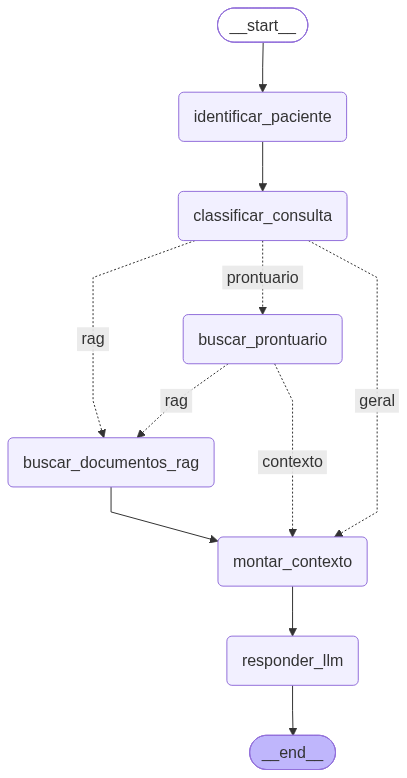

In [231]:
from IPython.display import Image, display

display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

# Testes finais do Assistente de IA

Nesta etapa, executamos o assistente utilizando diferentes tipos de consultas para validar o fluxo do LangGraph e a integração entre a LLM customizada, o prontuário e o RAG.

## Pergunta geral

Testamos uma pergunta sobre diabetes que não está relacionada a um paciente específico.

## Pergunta contextualizada

Testamos uma pergunta utilizando os dados específicos de um paciente.

## Pergunta combinada

Testamos uma consulta que utiliza simultaneamente os dados do paciente e informações recuperadas pelo RAG.

In [232]:
estado = {
    "pergunta": "O que é diabetes tipo 2?"
}

resultado = app.invoke(estado)

print("=" * 80)
print("RESULTADO FINAL")
print("=" * 80)

print(f"Pergunta: {resultado['pergunta']}")
print()
print("Resposta:")
print(resultado["resposta"])

print("=" * 80)

NÓ -> identificar_paciente
Pergunta............: O que é diabetes tipo 2?
ℹ️ Nenhum paciente identificado.
NÓ -> classificar_consulta
Prontuário necessário: NÃO
RAG necessário: NÃO
Fine-tuning: SIM (conhecimento médico especializado)
➡️ Rota: conhecimento da LLM
NÓ -> montar_contexto
Nenhum prontuário associado à pergunta.
Contexto médico criado.
Chunks utilizados pelo RAG: 0
NÓ -> responder_llm
Integrando:
✓ Conhecimento médico especializado (Fine-tuning)

Enviando contexto para a LLM customizada...

Resposta recebida da LLM.
RESULTADO FINAL
Pergunta: O que é diabetes tipo 2?

Resposta:
Diabetes tipo 2 é uma doença crônica caracterizada por alterações no metabolismo de glicose do sangue, resultantes de resistência ou insuficiência das células beta do pâncreas. O tratamento envolve mudanças nos hábitos alimentares, exercícios físicos regulares e medicamentos para controlar os níveis de glicose no sangue.
                
A doença pode ser diagnosticada com testes de glicemia no sangue.

In [233]:
estado = {
    "pergunta": (
        "A Maria Silva está com o diabetes controlado "
        "considerando seus últimos exames?"
    )
}

resultado = app.invoke(estado)

print("=" * 80)
print("RESULTADO FINAL")
print("=" * 80)

print(f"Pergunta: {resultado['pergunta']}")
print()
print("Resposta:")
print(resultado["resposta"])

print("=" * 80)

NÓ -> identificar_paciente
Pergunta............: A Maria Silva está com o diabetes controlado considerando seus últimos exames?
Paciente encontrado.: Maria Silva
NÓ -> classificar_consulta
Prontuário necessário: SIM
RAG necessário: NÃO
Fine-tuning: SIM (conhecimento médico especializado)
➡️ Rota: prontuário
NÓ -> buscar_prontuario
Paciente.............: Maria Silva
✅ Prontuário encontrado.
NÓ -> montar_contexto
Montando contexto para Maria Silva
Contexto médico criado.
Chunks utilizados pelo RAG: 0
NÓ -> responder_llm
Integrando:
✓ Conhecimento médico especializado (Fine-tuning)
✓ Dados específicos do paciente (Prontuário)

Enviando contexto para a LLM customizada...

Resposta recebida da LLM.
RESULTADO FINAL
Pergunta: A Maria Silva está com o diabetes controlado considerando seus últimos exames?

Resposta:
Para responder corretamente, você precisa analisar a situação do paciente Maria Silva. Ela tem diabetes tipo 2 e hipertensão arterial. Seus níveis de glicemia de jejum são altos (17

In [234]:
estado = {
    "pergunta": (
        "A Maria Silva precisa melhorar a alimentação. "
        "Segundo o manual, quantos carboidratos existem "
        "em uma colher de sopa de abobrinha italiana cozida?"
    )
}

resultado = app.invoke(estado)

print("=" * 80)
print("RESULTADO FINAL")
print("=" * 80)

print(f"Pergunta: {resultado['pergunta']}")
print()
print("Resposta:")
print(resultado["resposta"])

print("=" * 80)

NÓ -> identificar_paciente
Pergunta............: A Maria Silva precisa melhorar a alimentação. Segundo o manual, quantos carboidratos existem em uma colher de sopa de abobrinha italiana cozida?
Paciente encontrado.: Maria Silva
NÓ -> classificar_consulta
Prontuário necessário: SIM
RAG necessário: SIM
Fine-tuning: SIM (conhecimento médico especializado)
➡️ Rota: prontuário + RAG
NÓ -> buscar_prontuario
Paciente.............: Maria Silva
✅ Prontuário encontrado.
NÓ -> buscar_documentos_rag
Pergunta: A Maria Silva precisa melhorar a alimentação. Segundo o manual, quantos carboidratos existem em uma colher de sopa de abobrinha italiana cozida?

Consultando base vetorial...
Documentos recuperados pela busca vetorial: 4

Consultando registros estruturados...
Registros encontrados por busca textual: 2

Total de documentos utilizados: 6

--------------------------------------------------------------------------------
CHUNK 1
---------------------------------------------------------------------